In [1]:
# +----------------------------------------------------------------------------+
# |                                                                            |
# |       .-"""""""-.             ___                                          |
# |     .'           '.       _,~"                                             |
# |    /          .##.  \   ,~"                                                |
# |   |           '##'  |~"                                                    |
# |    \                /~,                                                    |
# |     '.            .'   "~,_                                                |
# |       '-........-'        "~,__                                            |
# |                                                                            |
# | Author    : Yatharth Bhasin (yatharth1997+ts@gmail.com)                    |
# | Date      : November 2026                                                  |
# | Copyright (c) 2026 Yatharth Bhasin                                         |
# | License-Identifier: MIT                                                    |
# +----------------------------------------------------------------------------+

# LED control voltage vs sample intensity

How much light reaches the sample for a given LED control voltage, on each scope and for each LED colour?
A light meter at the sample plane reads the light while the control voltage is stepped. A straight line per
LED then converts control voltage into photon flux density (PFD, µmol/m²/s). The acquisition script stores
that line on the scope, for later experiments.

*Analysis written by Claude (Anthropic); conceptualised and verified by Yatharth Bhasin.*

## Protocol

Acquisition: `single_channel_calibration()` in
[`scripts/calibration/control_volt_vs_sample_intensity.py`](https://github.com/Trappy-Scopes/trappyscopes/blob/main/scripts/calibration/control_volt_vs_sample_intensity.py).

- **Light meter:** `lux1`, a TSL2561 on a Seeed Grove Digital Light Sensor, read by its own Pico at 16× gain
  and 101 ms. It sits on a 4.5 mm centring plate in the sample holder, about 5 mm above the sample-holder
  plane, and is moved from scope to scope.
- **Sweep:** one LED colour at a time, from 0 to 2.9 V in 0.1 V steps, first with the beacon off and then on.
  Each point waits 0.2 s, then takes one reading.
- **Repeats:** since trappyscopes `21b83ff` each sweep runs four times (up, down, up, down), about 16 min per
  scope. Earlier runs swept up once per beacon state.
- **PWM:** the LED driver is PWM at 3 MHz, which gives 42 duty levels, so the light changes in steps of
  3.3/42 V whatever voltage is asked for.

**Running in Colab.** Open this notebook with the *Open in Colab* button on its page. The next cell runs only
in Colab: it installs what Colab lacks and asks for a `.zip` of your experiment folders.

In [2]:
import os, subprocess, sys
if "google.colab" in sys.modules:                         # skipped everywhere else
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "trappy-explorer @ git+https://github.com/Trappy-Scopes/trappy-explorer.git"], check=True)
    from google.colab import files
    for name in files.upload():                           # a .zip of your experiment folders
        subprocess.run(["unzip", "-q", "-o", name, "-d", "/content/data"], check=True)
    root = "/content/data"
    while True:                                           # step into a single wrapping folder
        subs = [d for d in os.listdir(root) if not d.startswith(("__MACOSX", "."))]
        if len(subs) == 1 and not os.path.exists(os.path.join(root, subs[0], "experiment.yaml")):
            root = os.path.join(root, subs[0])
        else:
            break
    os.environ["CALIBRATION_DATA"] = root

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import rich, yaml
from scipy import stats
from explorer.legacy import ExpExplorer

DATA = os.environ.get("CALIBRATION_DATA", "/Users/byatharth/Downloads/2026_11_16_light_calib_test1_normalzpos_1pt4to6")   # set to your own runs
OUT = "results"                                        # the fleet table is written here
SCOPES = [f"M{i}" for i in range(1, 9)]
COLORS = dict(zip(SCOPES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                           "#e87ba4", "#008300", "#6250d6", "#e34948"]))
LED = {"red": "#e34948", "green": "#1baf7a", "blue": "#2a78d6"}
sns.set_theme(style="ticks", rc={"axes.grid": True, "grid.color": "#e8e8e6",
                                 "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                                 "lines.linewidth": 1.2, "legend.frameon": False})

## Data

Runs are read with trappy-explorer's legacy reader, `explorer.legacy.ExpExplorer`. Each run has one stream per
LED colour (`red`, `green`, `blue`), one row per reading. Each run also records what the light meter reported
about itself (`devices/lightmeter/config`), and the fit the script stored on the scope (`devices/<colour>/params`).

In [4]:
rich.get_console().quiet = True                           # the loader prints one line per run
exps = ExpExplorer.create_superset(DATA, extended_parse=True)
rich.get_console().quiet = False
print(exps)

ms = exps.df_events.query("type == 'measurement_stream'")
res = exps.df.assign(stream=exps.df.measureid.map(dict(zip(ms.measureid, ms.name))))
meta = {eid: d["metadata"] for eid, d in exps.data.items()}

def sensor_of(m):
    return (m.get("devices", {}).get("lightmeter") or {}).get("config") or {}

runs = pd.DataFrame([{"scope": m["name"].split("__")[0], "eid": eid, "started": m["created"],
                      **{k: sensor_of(m).get(k) for k in ("board", "chip", "gain", "integration_ms")}}
                     for eid, m in meta.items()]).set_index("scope").sort_index()
runs = runs.join(res.groupby(["eid", "stream"]).size().unstack(fill_value=0), on="eid")
runs

<Experiments :: 8  datasets [extended_parse]>
  |- eid: c22ebed2d0
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: d5e8160c13
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: f4834f8de2
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: 6803d5cab2
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: b9bdec488a
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: 8ed9e0ca28
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: e8eb1fd84e
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue
  |- eid: d5618f5bb5
  	|- m-stream: red
  	|- m-stream: green
  	|- m-stream: blue



,eid,started,board,chip,gain,integration_ms,blue,green,red
scope,,,,,,,,,
M1,b9bdec488a,2026-11-16 17:55:38.971411,lux1,TSL2561T/FN/CL,16,101,60,60,60
M2,f4834f8de2,2026-11-16 18:04:40.471122,lux1,TSL2561T/FN/CL,16,101,60,60,60
M3,d5618f5bb5,2026-11-16 16:55:01.794833,lux1,TSL2561T/FN/CL,16,101,60,60,60
M4,c22ebed2d0,2026-11-16 17:04:28.566716,lux1,TSL2561T/FN/CL,16,101,60,60,60
M5,e8eb1fd84e,2026-11-16 17:19:47.543886,lux1,TSL2561T/FN/CL,16,101,60,60,60
M6,8ed9e0ca28,2026-11-16 17:25:48.154012,lux1,TSL2561T/FN/CL,16,101,60,60,60
M7,6803d5cab2,2026-11-16 17:40:35.408228,lux1,TSL2561T/FN/CL,16,101,60,60,60
M8,d5e8160c13,2026-11-16 17:47:52.895710,lux1,TSL2561T/FN/CL,16,101,60,60,60


In [5]:
eid = runs.eid.iloc[0]                                    # one run's folder, as an example
tree = exps.data[eid]["filetree"]["."]
print(os.path.basename(exps.get_parent_dir(eid)))
for f in sorted(tree["files"]) + sorted(k + "/" for k in tree if k != "files"):
    print("   ", f)

print()
skip = {"eid", "type", "measureid", "measureidx", "mid", "sid", "scriptid", "success", "dt",
        "exptime", "attribs", "machinetime", "sessiontime", "scopeid", "stream"}
for name, g in res.groupby("stream"):
    cols = [c for c in g.dropna(axis=1, how="all").columns if c not in skip]
    print(f"{name:10s} {len(g):5d} rows   {', '.join(cols)}")

notes = exps.df_events.query("type == 'user_note'")
notes.assign(scope=notes.eid.map(runs.reset_index().set_index("eid").scope)).reindex(columns=["scope", "dt", "note"])

M1__YB__2026_11_16__17hh_55mm__light_calibration_volt_vs_intensity__b9bdec488a
    calib_image.png
    control_volt_vs_intensity_calibration_plot.png
    experiment.yaml
    logs.yaml
    sessions.yaml
    alignment/
    analysis/
    converted/
    postprocess/
    scripts/

blue         480 rows   beacon, ch1, channels, counts, saturated, temp, volts
green        480 rows   beacon, ch1, channels, counts, saturated, temp, volts
red          480 rows   beacon, ch1, channels, counts, saturated, temp, volts


,scope,dt,note
18,M8,2026-11-16 17:54:14.751470,Light at the end is green and not blue. Strange.
45,M1,2026-11-16 17:56:16.070814,Realignment done to about 1.5x from the lower ...
46,M1,2026-11-16 17:56:41.548408,Older mag of 1.61 restored and checked. Now do...


### Sweep labels for runs recorded before 17 Nov 2026

Until trappyscopes `3252c69`, the script swept each colour once with the beacon off and once with it on, both
upwards, and recorded no `sweep` or `direction`. For those runs the two sweeps are numbered here in the order
they were taken. In a later run, missing labels stop the notebook instead.

In [6]:
FIX = pd.Timestamp("2026-11-17")                          # trappyscopes 3252c69 / 21b83ff
before_fix = lambda scope: pd.Timestamp(runs.loc[scope, "started"]) < FIX
scope_of = runs.reset_index().set_index("eid").scope

d = res.assign(scope=res.eid.map(scope_of), channel=res.stream, t=pd.to_datetime(res.dt),
               V=res.volts.apply(lambda v: float(v[0]) if isinstance(v, (list, tuple)) else float(v)),
               counts=res.counts.astype(float), ch1=res.ch1.astype(float),
               beacon=res.beacon.astype(bool), saturated=res.saturated.astype(bool))
for s in d.scope.unique():
    rows = d.scope == s
    if "sweep" in d and d.loc[rows, "sweep"].notna().all():
        continue
    assert before_fix(s), f"{s}: no sweep labels in a run recorded after the fix"
    d.loc[rows, "sweep"] = d.loc[rows, "beacon"].astype(int)
    d.loc[rows, "direction"] = "up"
d["sweep"] = d.sweep.astype(int)
d = d[["scope", "eid", "channel", "V", "beacon", "sweep", "direction", "counts", "ch1", "saturated", "temp", "t"]]
d.groupby(["scope", "beacon", "sweep", "direction"]).size().unstack(["beacon", "sweep", "direction"])

beacon,False,True
sweep,0,1
direction,up,up
scope,,
M1,90,90
M2,90,90
M3,90,90
M4,90,90
M5,90,90
M6,90,90
M7,90,90


## The light meter

The conversion constants hold only for the chip, gain and integration time they were measured for. They come
from the TAOS TSL2560/TSL2561 datasheet (TAOS059N, March 2009), TSL2561T/FN/CL column:

- `Re_640nm`: ch0 counts per µW/cm² at 640 nm, 16× gain, 101 ms (typical). The same table allows 750–1250
  counts for a nominal 1000, so the absolute scale is good to ±25% between chips. Scope-to-scope comparisons
  do not depend on it, because one sensor measures every scope.
- `colour_factors`: ch0 responsivity at each LED's peak wavelength relative to 640 nm, read off Figure 4.

Each run's sensor report must match.

In [7]:
SENSOR = {"chip": "TSL2561T/FN/CL", "gain": 16, "integration_ms": 101,
          "Re_640nm": 27.5, "colour_factors": {"red": 1.00, "green": 0.91, "blue": 0.81},
          "full_scale": 37177}
check = runs[["board", "chip", "gain", "integration_ms"]].assign(
    matches=lambda r: (r.chip == SENSOR["chip"]) & (r.gain == SENSOR["gain"])
                      & (r.integration_ms == SENSOR["integration_ms"]))
assert check.matches.all(), "a run's light meter does not match the constants"
check

,board,chip,gain,integration_ms,matches
scope,,,,,
M1,lux1,TSL2561T/FN/CL,16,101,True
M2,lux1,TSL2561T/FN/CL,16,101,True
M3,lux1,TSL2561T/FN/CL,16,101,True
M4,lux1,TSL2561T/FN/CL,16,101,True
M5,lux1,TSL2561T/FN/CL,16,101,True
M6,lux1,TSL2561T/FN/CL,16,101,True
M7,lux1,TSL2561T/FN/CL,16,101,True
M8,lux1,TSL2561T/FN/CL,16,101,True


### Which LED each channel lights

The sensor's second photodiode (ch1) sees mostly near-infrared, so the ratio ch1/ch0 depends on the
wavelength: highest for red, low for green, lowest for blue. Each point is one channel on one scope, at
1 V and above. A channel whose ratio sits with another colour lights that colour's LED. From here on each
channel is analysed as the colour it actually lights; the table lists any that differ from their name.

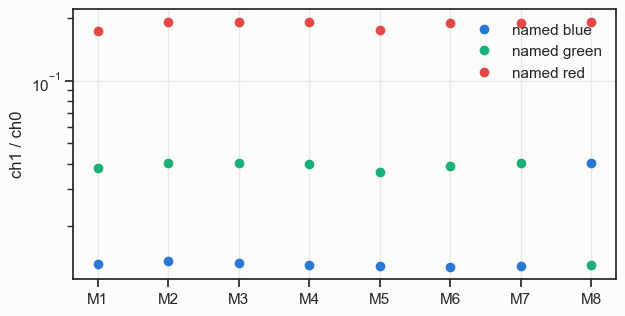

,scope,channel,colour
21,M8,blue,green
22,M8,green,blue


In [8]:
r = d[d.V >= 1].assign(ratio=lambda x: x.ch1 / x.counts).groupby(["scope", "channel"]).ratio.median()
measured = r.apply(lambda v: "red" if v > 0.1 else ("green" if v > 0.025 else "blue")).rename("colour")
d = d.join(measured, on=["scope", "channel"])

fig, ax = plt.subplots(figsize=(7, 3.5))
for ch, g in r.rename("ratio").reset_index().groupby("channel"):
    g = g.set_index("scope").reindex(SCOPES)
    ax.plot(SCOPES, g.ratio, "o", color=LED[ch], label=f"named {ch}")
ax.set_ylabel("ch1 / ch0"); ax.set_yscale("log"); ax.legend()
plt.show()
measured.reset_index().query("channel != colour")

## PWM levels

The control voltage sets a PWM duty cycle. At 3 MHz on the Pico's 125 MHz clock there are 42 levels, and
MicroPython 1.25 rounds each requested duty to the nearest one. The plot shows the voltage asked for against
the voltage the PWM actually produces: equal steps would lie on a straight staircase; uneven steps are where
two 0.1 V requests land one level apart or two. The fits below use the produced voltage.

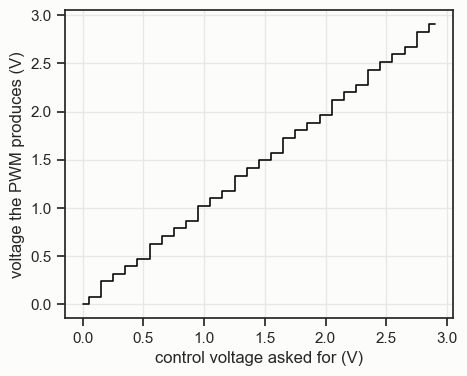

In [9]:
PWM_LEVELS, VREF = 42, 3.3
duty = 65535 - (d.V / VREF * 65535).astype(int)           # pwm_ca_channel.setV (common anode)
d["level"] = PWM_LEVELS - (duty * PWM_LEVELS + 65535 // 2) // 65535
d["V_pwm"] = d.level * VREF / PWM_LEVELS
produced = lambda V: (PWM_LEVELS - ((65535 - int(V / VREF * 65535)) * PWM_LEVELS + 65535 // 2)
                      // 65535) * VREF / PWM_LEVELS    # the same, for one requested voltage

v = d[["V", "V_pwm"]].drop_duplicates().sort_values("V")
fig, ax = plt.subplots(figsize=(5, 4))
ax.step(v.V, v.V_pwm, where="mid", color="#0b0b0b")
ax.set_xlabel("control voltage asked for (V)"); ax.set_ylabel("voltage the PWM produces (V)")
plt.show()

## Raw readings

Sensor counts (ch0) against the control voltage, every reading, one panel per scope, coloured by the LED each
channel actually lights. Readings that sit on top of each other were repeatable. The flat start is the LED
below its threshold; the small steps along each line are the PWM levels.

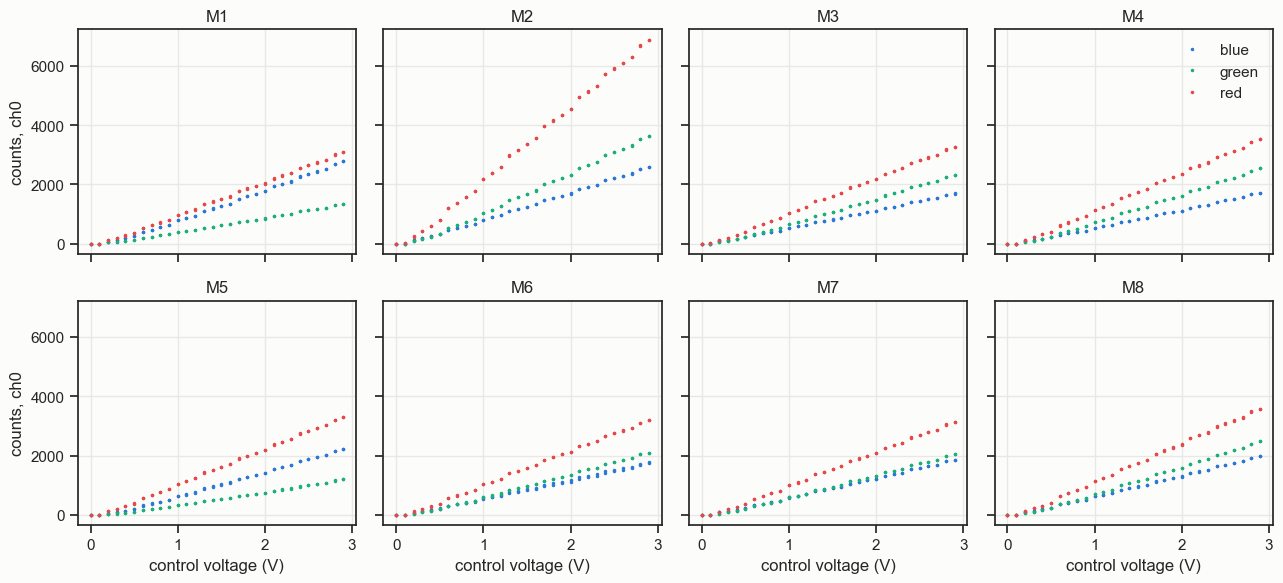

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SCOPES):
    for colour, g in d[d.scope == s].groupby("colour"):
        ax.plot(g.V, g.counts, ".", ms=3, color=LED[colour], label=colour)
    ax.set_title(s)
for ax in axes[-1]:
    ax.set_xlabel("control voltage (V)")
for ax in axes[:, 0]:
    ax.set_ylabel("counts, ch0")
axes[0, -1].legend()
plt.tight_layout(); plt.show()

## Photon flux density

ch0 counts give the irradiance at the sensor, E = counts / (Re_640nm × colour factor) µW/cm². For a
narrow-band LED the photon flux density is PFD = E[W/m²] × λ[nm] / 119.6 µmol/m²/s, with λ each scope's own
`lambda_nm` for that colour. Readings at the sensor's full-scale count are the ceiling, not the light, and are
left out of the fits; the table counts them.

In [11]:
lam = {(scope_of[eid], c): m["devices"][c]["params"]["lambda_nm"]
       for eid, m in meta.items() for c in ("red", "green", "blue")}
re = lambda colour: SENSOR["Re_640nm"] * SENSOR["colour_factors"][colour]
d["pfd"] = [c / re(k) * 0.01 * lam[(s, k)] / 119.6 for c, k, s in zip(d.counts, d.colour, d.scope)]
d.groupby(["scope", "colour"]).saturated.sum().unstack().reindex(SCOPES)

colour,blue,green,red
scope,,,
M1,0,0,0
M2,0,0,0
M3,0,0,0
M4,0,0,0
M5,0,0,0
M6,0,0,0
M7,0,0,0
M8,0,0,0


## Fit

One straight line per scope and colour, PFD = slope × V + intercept, against the produced voltage, over all
readings from level 3 (about 0.2 V) up; below that the LED gives no light. `resid_sd_pct` is the scatter
about the line as % of the PFD at full scale. The lack-of-fit test compares how far the readings at each level
sit from the line with how far they sit from each other: `lof_p` below 0.05 means the line misses by more
than the readings scatter, i.e. the response is not quite straight.

In [12]:
fitted = d[(d.level >= 3) & ~d.saturated]

def fit(g):
    (m, c), cov = np.polyfit(g.V_pwm, g.pfd, 1, cov=True)
    res = g.pfd - (m * g.V_pwm + c)
    ss_res, top = (res ** 2).sum(), m * g.V_pwm.max() + c
    ss_pe = g.groupby("level").pfd.apply(lambda y: ((y - y.mean()) ** 2).sum()).sum()
    L, N = g.level.nunique(), len(g)
    F = ((ss_res - ss_pe) / (L - 2)) / (ss_pe / (N - L))
    return pd.Series({"slope": m, "intercept": c, "slope_se": np.sqrt(cov[0, 0]),
                      "r2": 1 - ss_res / ((g.pfd - g.pfd.mean()) ** 2).sum(),
                      "resid_sd_pct": 100 * np.sqrt(ss_res / (N - 2)) / top,
                      "readings_per_level": N / L, "lof_p": stats.f.sf(F, L - 2, N - L)})

fits = fitted.groupby(["scope", "colour"]).apply(fit, include_groups=False)
fits.round(4)

slope  intercept  slope_se      r2  resid_sd_pct  \
scope colour                                                      
M1    blue    1.8076    -0.4364    0.0064  0.9993        0.7981   
      green   0.8583    -0.1781    0.0037  0.9990        0.9774   
      red     2.1362    -0.3116    0.0024  0.9999        0.2494   
M2    blue    1.6324    -0.2230    0.0031  0.9998        0.4185   
      green   2.3674    -0.5474    0.0066  0.9996        0.6303   
      red     4.7633    -0.6995    0.0033  1.0000        0.1530   
M3    blue    1.0599    -0.1369    0.0021  0.9998        0.4358   
      green   1.5053    -0.3363    0.0040  0.9996        0.6054   
      red     2.2626    -0.3127    0.0022  0.9999        0.2123   
M4    blue    1.0754    -0.1434    0.0021  0.9998        0.4263   
      green   1.6482    -0.3789    0.0044  0.9996        0.6062   
      red     2.4427    -0.3499    0.0021  1.0000        0.1848   
M5    blue    1.4474    -0.3426    0.0056  0.9992        0.8807   
      green   0.7736    -0.1954    0.0045  0.9982        1.3274   
      red     2.2845    -0.3247    0.0016  1.0000        0.1510   
M6    blue    1.1026    -0.1489    0.0053  0.9987        1.0509   
      green   1.3669    -0.3169    0.0043  0.9995        0.7116   
      red     2.2179    -0.3055    0.0027  0.9999        0.2659   
M7    blue    1.1683    -0.1527    0.0021  0.9998        0.3882   
      green   1.3277    -0.3020    0.0034  0.9996        0.5754   
      red     2.1703    -0.3020    0.0022  0.9999        0.2219   
M8    blue    1.2486    -0.1659    0.0024  0.9998        0.4242   
      green   1.6093    -0.3697    0.0045  0.9996        0.6256   
      red     2.4822    -0.3548    0.0022  1.0000        0.1952   

              readings_per_level   lof_p  
scope colour                              
M1    blue                   2.0  0.0000  
      green                  2.0  0.0000  
      red                    2.0  0.9792  
M2    blue                   2.0  0.0000  
      green                  2.0  0.0000  
      red                    2.0  0.0000  
M3    blue                   2.0  0.0000  
      green                  2.0  0.0000  
      red                    2.0  0.0000  
M4    blue                   2.0  0.0000  
      green                  2.0  0.0000  
      red                    2.0  0.0000  
M5    blue                   2.0  0.0001  
      green                  2.0  0.0000  
      red                    2.0  0.0015  
M6    blue                   2.0  0.9997  
      green                  2.0  0.0000  
      red                    2.0  0.0000  
M7    blue                   2.0  0.0000  
      green                  2.0  0.0000  
      red                    2.0  0.0000  
M8    blue                   2.0  0.0000  
      green                  2.0  0.0000  
      red                    2.0  0.0000

Each scope's readings (points) and fitted lines, PFD against the produced voltage. Points far from their line,
or a line that bends away from the points at either end, show where a straight line does not describe the LED.

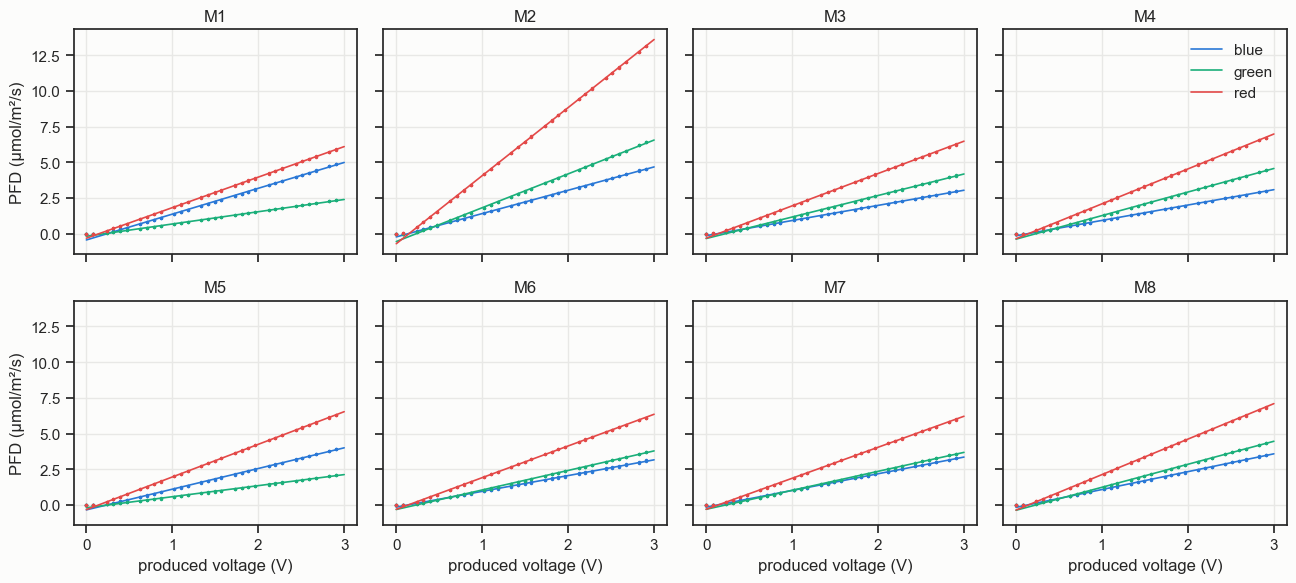

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharex=True, sharey=True)
x = np.linspace(0, 3, 2)
for ax, s in zip(axes.flat, SCOPES):
    for colour, g in d[d.scope == s].groupby("colour"):
        f = fits.loc[(s, colour)]
        ax.plot(g.V_pwm, g.pfd, ".", ms=3, color=LED[colour])
        ax.plot(x, f.slope * x + f.intercept, color=LED[colour], label=colour)
    ax.set_title(s)
for ax in axes[-1]:
    ax.set_xlabel("produced voltage (V)")
for ax in axes[:, 0]:
    ax.set_ylabel("PFD (µmol/m²/s)")
axes[0, -1].legend()
plt.tight_layout(); plt.show()

Residuals from each scope's line, averaged at each level, as % of the PFD at full scale. A flat band around
zero means the line fits; a curve that is high at both ends and low in the middle means the response bends
upwards.

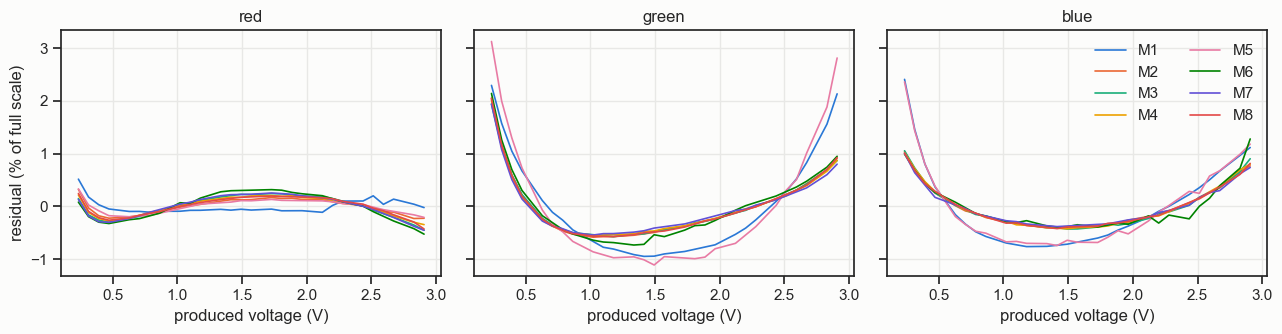

In [14]:
f = fits.reset_index()[["scope", "colour", "slope", "intercept"]]
rr = fitted.merge(f, on=["scope", "colour"])
rr["resid_pct"] = 100 * (rr.pfd - (rr.slope * rr.V_pwm + rr.intercept)) / (rr.slope * 2.9 + rr.intercept)
rr = rr.groupby(["scope", "colour", "V_pwm"]).resid_pct.mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, colour in zip(axes, LED):
    for s in SCOPES:
        g = rr[(rr.scope == s) & (rr.colour == colour)]
        ax.plot(g.V_pwm, g.resid_pct, color=COLORS[s], label=s)
    ax.set_title(colour); ax.set_xlabel("produced voltage (V)")
axes[0].set_ylabel("residual (% of full scale)"); axes[-1].legend(ncol=2)
plt.tight_layout(); plt.show()

## Hysteresis

At each level, the mean of the readings taken on the way up minus those taken on the way down, as % of the PFD
at full scale. Zero means the light does not depend on the direction of approach. A consistent sign means the
LED (or the light meter) lags: on the way up readings come out low if the light has not settled, on the way
down high. Runs without a downward sweep cannot show this.

In [15]:
has_down = d.groupby("scope").direction.apply(lambda x: (x == "down").any())
print("scopes with a downward sweep:", list(has_down[has_down].index) or "none")
hyst = pd.DataFrame({"scope": [], "colour": [], "V_pwm": [], "hyst_pct": []})
if has_down.any():
    h = fitted[fitted.scope.isin(has_down[has_down].index)]
    h = h.pivot_table(index=["scope", "colour", "V_pwm"], columns="direction", values="pfd")
    full = fits.slope * 2.9 + fits.intercept
    h["hyst_pct"] = 100 * (h["up"] - h["down"]) / full.reindex(h.index.droplevel("V_pwm")).to_numpy()
    hyst = h.hyst_pct.reset_index()
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
    for ax, colour in zip(axes, LED):
        for s in SCOPES:
            g = hyst[(hyst.scope == s) & (hyst.colour == colour)]
            ax.plot(g.V_pwm, g.hyst_pct, color=COLORS[s], label=s)
        ax.set_title(colour); ax.set_xlabel("produced voltage (V)")
    axes[0].set_ylabel("up − down (% of full scale)"); axes[-1].legend(ncol=2)
    plt.tight_layout(); plt.show()
hyst_tab = hyst.assign(a=lambda x: x.hyst_pct.astype(float).abs()).groupby(["scope", "colour"]).a.max().rename("hysteresis_max_pct")

scopes with a downward sweep: none


## Repeatability and the beacon

`repeat_pct`: the spread of all readings at the same level (std / mean), median over levels from 1 V up, where
one count is below 0.1% of the reading.

`beacon_pct`: how much higher readings are with the beacon on than off, median over the same levels. The
beacon-on sweeps always come after the beacon-off sweeps, so this also contains any drift between them.
`beacon_dark_counts` separates the two: it is the beacon's own light, read with the LED off (levels 0 and 1),
beacon on minus off. Near zero means the beacon adds no light at the sample, and any `beacon_pct` is drift.

In [16]:
hi = fitted[fitted.V_pwm >= 1]
repeat = hi.groupby(["scope", "colour", "level"]).pfd.agg(lambda y: 100 * y.std() / y.mean())
repeat = repeat.groupby(["scope", "colour"]).median().rename("repeat_pct")
b = hi.pivot_table(index=["scope", "colour", "level"], columns="beacon", values="pfd")
beacon = (100 * (b[True] / b[False] - 1)).groupby(["scope", "colour"]).median().rename("beacon_pct")
dark = d[d.level <= 1].groupby(["scope", "beacon"]).counts.mean().unstack()
beacon_dark = (dark[True] - dark[False]).rename("beacon_dark_counts")
tab = pd.concat([repeat, beacon], axis=1).unstack("colour").reindex(SCOPES)
tab[("beacon_dark_counts", "")] = beacon_dark.reindex(SCOPES)
tab.round(3)

repeat_pct               beacon_pct               beacon_dark_counts
colour       blue  green    red       blue  green    red                   
scope                                                                      
M1          0.151  0.185  0.733      0.214  0.262  1.042              0.000
M2          0.200  0.084  0.092      0.284  0.118 -0.130             -0.167
M3          0.145  0.095  0.096      0.205  0.134 -0.136              0.000
M4          0.114  0.000  0.115      0.161  0.000 -0.163              0.000
M5          1.199  1.398  0.163      1.710  1.997 -0.230              0.000
M6          2.401  0.358  0.127      3.454  0.508 -0.168              0.000
M7          0.050  0.000  0.150      0.071  0.000 -0.211              0.000
M8          0.266  0.043  0.131      0.376  0.060 -0.185              0.000

## Fleet

Each scope's slope (PFD per volt) for each colour. Scopes on a horizontal line deliver the same light for the
same control voltage; distance from the others is how much a scope needs its own calibration.

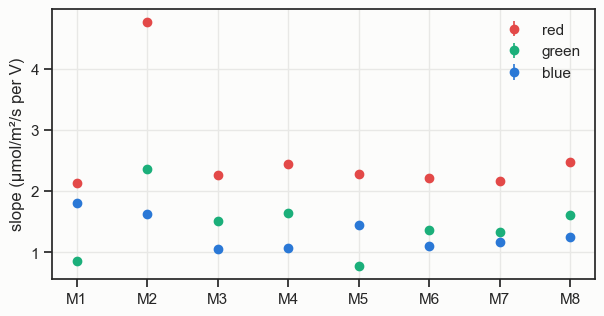

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for colour in LED:
    g = fits.xs(colour, level="colour").reindex(SCOPES)
    ax.errorbar(SCOPES, g.slope, yerr=g.slope_se, fmt="o", color=LED[colour], label=colour)
ax.set_ylabel("slope (µmol/m²/s per V)"); ax.legend()
plt.show()

## What the script stored on the scope

The script fits its own line when the run ends and stores it on the scope, one per channel. It fits against the
voltage asked for, over every reading including the dead zone. This table compares the stored line's prediction
with this notebook's fit at 1 V and 2 V asked for. The light at a requested voltage is that of the PWM level it
lands on, so a line fitted against the requested voltage is off by up to half a step there.

Green and blue convert to PFD almost identically with this sensor (λ divided by the colour factor is about 577
for both). So a channel that lights the other of those two colours still stores a line that is right for the
light it delivers; only its colour is wrong.

In [18]:
rows = []
for eid, m in meta.items():
    s = scope_of[eid]
    for ch in ("red", "green", "blue"):
        p = m["devices"][ch]["params"]
        colour = measured[(s, ch)]
        f = fits.loc[(s, colour)]
        row = {"scope": s, "channel": ch, "colour": colour, "stored_eid": p.get("calib_eid"),
               "shelf_slope": float(p["calib_slope"]), "shelf_intercept": float(p["calib_intercept"])}
        for V in (1.0, 2.0):
            ours = f.slope * produced(V) + f.intercept
            row[f"shelf_vs_fit_{V:g}V_pct"] = 100 * ((row["shelf_slope"] * V + row["shelf_intercept"]) / ours - 1)
        rows.append(row)
shelf = pd.DataFrame(rows).set_index(["scope", "channel"]).sort_index()
shelf.round(3)

colour  stored_eid  shelf_slope  shelf_intercept  \
scope channel                                                    
M1    blue      blue  b9bdec488a        1.763           -0.346   
      green    green  b9bdec488a        0.841           -0.142   
      red        red  b9bdec488a        2.108           -0.254   
M2    blue      blue  f4834f8de2        1.613           -0.182   
      green    green  f4834f8de2        2.312           -0.435   
      red        red  f4834f8de2        4.701           -0.570   
M3    blue      blue  d5618f5bb5        1.048           -0.112   
      green    green  d5618f5bb5        1.471           -0.267   
      red        red  d5618f5bb5        2.235           -0.255   
M4    blue      blue  c22ebed2d0        1.063           -0.118   
      green    green  c22ebed2d0        1.610           -0.301   
      red        red  c22ebed2d0        2.412           -0.286   
M5    blue      blue  e8eb1fd84e        1.413           -0.272   
      green    green  e8eb1fd84e        0.753           -0.154   
      red        red  e8eb1fd84e        2.256           -0.265   
M6    blue      blue  8ed9e0ca28        1.090           -0.121   
      green    green  8ed9e0ca28        1.335           -0.252   
      red        red  8ed9e0ca28        2.192           -0.250   
M7    blue      blue  6803d5cab2        1.155           -0.125   
      green    green  6803d5cab2        1.297           -0.240   
      red        red  6803d5cab2        2.144           -0.247   
M8    blue     green  d5e8160c13        1.573           -0.294   
      green     blue  d5e8160c13        1.234           -0.136   
      red        red  d5e8160c13        2.451           -0.290   

               shelf_vs_fit_1V_pct  shelf_vs_fit_2V_pct  
scope channel                                            
M1    blue                   0.522                2.125  
      green                  0.020                2.087  
      red                   -0.837                2.026  
M2    blue                  -0.949                2.016  
      green                  0.356                2.114  
      red                   -0.835                2.028  
M3    blue                  -1.012                2.008  
      green                  0.250                2.105  
      red                   -0.928                2.019  
M4    blue                  -0.994                2.013  
      green                  0.335                2.113  
      red                   -0.883                2.024  
M5    blue                   0.445                2.120  
      green                  0.730                2.136  
      red                   -0.889                2.023  
M6    blue                  -0.953                2.015  
      green                  0.366                2.115  
      red                   -0.951                2.019  
M7    blue                  -1.011                2.010  
      green                  0.296                2.110  
      red                   -0.932                2.020  
M8    blue                   0.374                2.154  
      green                 -1.029                1.970  
      red                   -0.882                2.024

## Results

In [19]:
fleet = (fits.join(hyst_tab).join(repeat).join(beacon).reset_index()
         .merge(shelf.reset_index()[["scope", "channel", "colour", "shelf_slope", "shelf_intercept",
                                     "shelf_vs_fit_1V_pct", "shelf_vs_fit_2V_pct"]], on=["scope", "colour"])
         .merge(runs.eid.reset_index(), on="scope").join(beacon_dark, on="scope"))
fleet["pfd_1V"] = fleet.slope * produced(1.0) + fleet.intercept       # the light you get asking for 1 V
fleet["pfd_2V"] = fleet.slope * produced(2.0) + fleet.intercept
fleet["saturated"] = fleet.apply(lambda r: int(d[(d.scope == r.scope) & (d.colour == r.colour)].saturated.sum()), axis=1)
fleet = fleet.set_index(["scope", "channel"]).sort_index()
fleet = fleet[["colour", "eid", "slope", "intercept", "slope_se", "pfd_1V", "pfd_2V", "r2", "resid_sd_pct",
               "lof_p", "readings_per_level", "hysteresis_max_pct", "repeat_pct", "beacon_pct",
               "beacon_dark_counts", "saturated",
               "shelf_slope", "shelf_intercept", "shelf_vs_fit_1V_pct", "shelf_vs_fit_2V_pct"]]
os.makedirs(OUT, exist_ok=True)
fleet.to_csv(f"{OUT}/led_control_volt_vs_sample_intensity.csv")
for eid, g in fleet.groupby("eid"):                       # one copy next to each run's data
    with open(os.path.join(exps.get_analysis_dir(eid), "led_control_volt_vs_sample_intensity.yaml"), "w") as fh:
        yaml.safe_dump({ch: {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}
                        for (_, ch), row in g.iterrows()}, fh)
fleet.round(4)

colour         eid   slope  intercept  slope_se  pfd_1V  pfd_2V  \
scope channel                                                                   
M1    blue      blue  b9bdec488a  1.8076    -0.4364    0.0064  1.4100  3.1143   
      green    green  b9bdec488a  0.8583    -0.1781    0.0037  0.6986  1.5078   
      red        red  b9bdec488a  2.1362    -0.3116    0.0024  1.8703  3.8844   
M2    blue      blue  f4834f8de2  1.6324    -0.2230    0.0031  1.4444  2.9835   
      green    green  f4834f8de2  2.3674    -0.5474    0.0066  1.8708  4.1029   
      red        red  f4834f8de2  4.7633    -0.6995    0.0033  4.1658  8.6569   
M3    blue      blue  d5618f5bb5  1.0599    -0.1369    0.0021  0.9457  1.9451   
      green    green  d5618f5bb5  1.5053    -0.3363    0.0040  1.2012  2.6205   
      red        red  d5618f5bb5  2.2626    -0.3127    0.0022  1.9984  4.1317   
M4    blue      blue  c22ebed2d0  1.0754    -0.1434    0.0021  0.9551  1.9691   
      green    green  c22ebed2d0  1.6482    -0.3789    0.0044  1.3046  2.8586   
      red        red  c22ebed2d0  2.4427    -0.3499    0.0021  2.1451  4.4483   
M5    blue      blue  e8eb1fd84e  1.4474    -0.3426    0.0056  1.1358  2.5005   
      green    green  e8eb1fd84e  0.7736    -0.1954    0.0045  0.5947  1.3241   
      red        red  e8eb1fd84e  2.2845    -0.3247    0.0016  2.0088  4.1628   
M6    blue      blue  8ed9e0ca28  1.1026    -0.1489    0.0053  0.9774  2.0170   
      green    green  8ed9e0ca28  1.3669    -0.3169    0.0043  1.0793  2.3681   
      red        red  8ed9e0ca28  2.2179    -0.3055    0.0027  1.9599  4.0510   
M7    blue      blue  6803d5cab2  1.1683    -0.1527    0.0021  1.0406  2.1421   
      green    green  6803d5cab2  1.3277    -0.3020    0.0034  1.0542  2.3060   
      red        red  6803d5cab2  2.1703    -0.3020    0.0022  1.9148  3.9611   
M8    blue     green  d5e8160c13  1.6093    -0.3697    0.0045  1.2740  2.7914   
      green     blue  d5e8160c13  1.2486    -0.1659    0.0024  1.1095  2.2867   
      red        red  d5e8160c13  2.4822    -0.3548    0.0022  2.1806  4.5210   

                   r2  resid_sd_pct   lof_p  readings_per_level  \
scope channel                                                     
M1    blue     0.9993        0.7981  0.0000                 2.0   
      green    0.9990        0.9774  0.0000                 2.0   
      red      0.9999        0.2494  0.9792                 2.0   
M2    blue     0.9998        0.4185  0.0000                 2.0   
      green    0.9996        0.6303  0.0000                 2.0   
      red      1.0000        0.1530  0.0000                 2.0   
M3    blue     0.9998        0.4358  0.0000                 2.0   
      green    0.9996        0.6054  0.0000                 2.0   
      red      0.9999        0.2123  0.0000                 2.0   
M4    blue     0.9998        0.4263  0.0000                 2.0   
      green    0.9996        0.6062  0.0000                 2.0   
      red      1.0000        0.1848  0.0000                 2.0   
M5    blue     0.9992        0.8807  0.0001                 2.0   
      green    0.9982        1.3274  0.0000                 2.0   
      red      1.0000        0.1510  0.0015                 2.0   
M6    blue     0.9987        1.0509  0.9997                 2.0   
      green    0.9995        0.7116  0.0000                 2.0   
      red      0.9999        0.2659  0.0000                 2.0   
M7    blue     0.9998        0.3882  0.0000                 2.0   
      green    0.9996        0.5754  0.0000                 2.0   
      red      0.9999        0.2219  0.0000                 2.0   
M8    blue     0.9996        0.6256  0.0000                 2.0   
      green    0.9998        0.4242  0.0000                 2.0   
      red      1.0000        0.1952  0.0000                 2.0   

               hysteresis_max_pct  repeat_pct  beacon_pct  beacon_dark_counts  \
scope channel                                                                   
M1

## Acceptance

This calibration writes to the scope, so it needs limits. The checks are: the light meter matches the
constants (checked above), no saturated readings, each channel lights the colour it is named after, and the
hysteresis, repeatability and fit residual stay within limits. The limits are not set yet; the values are in
the results table.

## Persistent records

This calibration writes 3 records to each scope: the shelves of its `red`, `green` and `blue` channels
(`~/red`, `~/green`, `~/blue`). Each holds the fitted line (`calib_slope`, `calib_intercept`,
`calib_cov_matrix`), the readings it was fitted on (`calib_volts`, `calib_counts`, `calib_pfd`), `calib_dt`,
`calib_sensor_gain`, the light meter's report (`calib_sensor`), the constants used (`calib_constants`), and the
run that produced it (`calib_eid`, `calib_exp_dir`).